## TTB948 Engineering Analysis and Optimisation

Part B: Optimisation

Session 3: Multivariate Optimisation




In [73]:
import numpy as np
import matplotlib.pyplot as plt


## Revision History

| Aspect | Value |
| ------ | ------ |
| Owner | Thomas Steffen |
| Location | Google colab / drive |
| Confidentiality | Public |

| Date | Update |
| ---- | ------ |
| 2026-11-17 | spawn |


In [74]:
from datetime import datetime
str(datetime.today())

'2026-11-24 16:51:17.109812'

## Define a simple regression problem



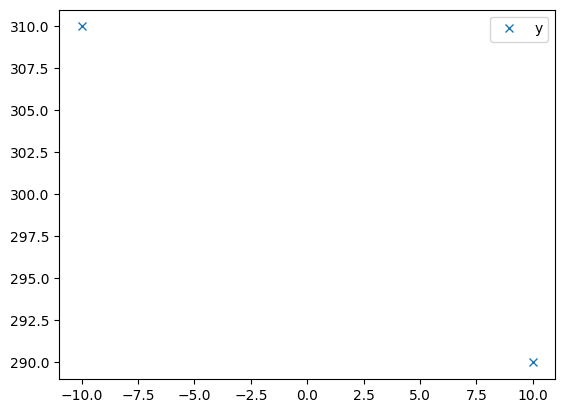

In [75]:
u0 = np.array([-10,10])
u = u0
y0 = np.array([310,290])
y = y0

plt.plot(u, y, 'x', label='y')
plt.legend()

## Linear basis functions

In [76]:
B = np.array([[1,-10],[1,10]])
print(B)
print(B.T@B)
print(np.linalg.eig(B))

[[  1 -10]
 [  1  10]]
[[  2   0]
 [  0 200]]
EigResult(eigenvalues=array([2.29843788, 8.70156212]), eigenvectors=array([[-0.99167541,  0.79226952],
       [ 0.12876289, -0.61017129]]))


## Mean Square Error


In [77]:
def mse(c):
  yd = B @ c - y
  return np.mean(yd**2)



## Contour plot

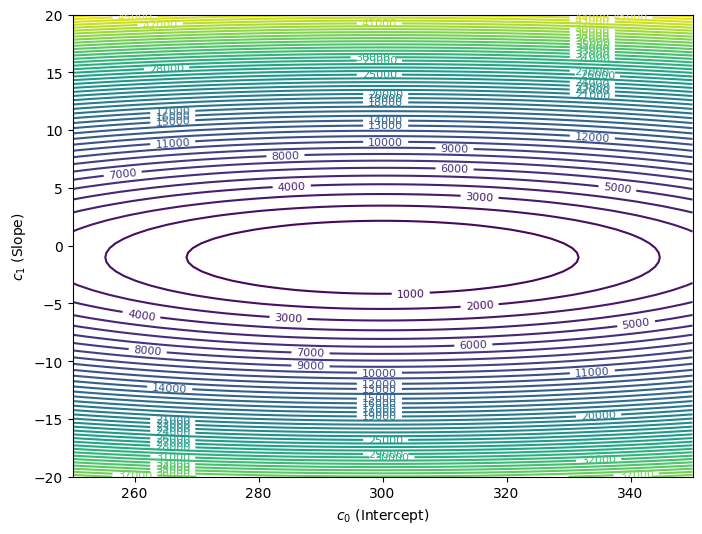

In [78]:
C0, C1 = np.mgrid[250:350:100j, -20:20:100j]
mse_vectorized = np.vectorize(lambda c0, c1: mse(np.array([c0, c1])))
Z = mse_vectorized(C0, C1)

plt.figure(figsize=(8, 6))
contours = plt.contour(C0, C1, Z, levels=50, cmap='viridis')
plt.clabel(contours, inline=True, fontsize=8)
plt.xlabel('$c_0$ (Intercept)')
plt.ylabel('$c_1$ (Slope)')
plt.show()

## Contour plot and gradient field

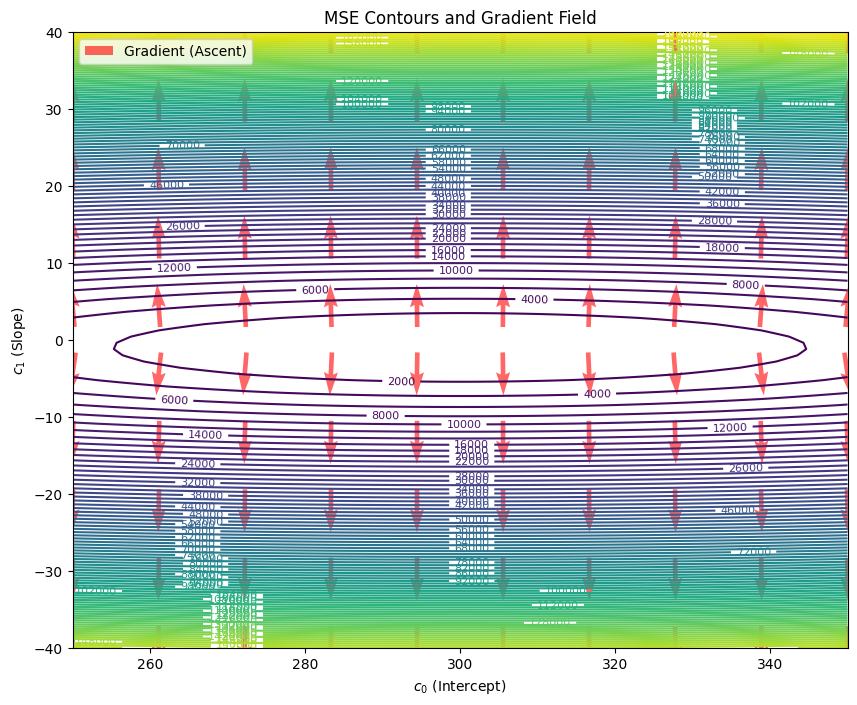

In [79]:
import numpy as np
import matplotlib.pyplot as plt

# Analytical gradient of MSE with respect to c = [c0, c1]
# MSE(c) = (1/N) * ||B @ c - y||^2
# grad(MSE) = (2/N) * B.T @ (B @ c - y)
def mse_gradient(c):
    yd = B @ c - y
    return (2.0 / len(y)) * (B.T @ yd)

# Create grid for contour and gradient quiver plot
# Using a slightly coarser grid for quiver arrows to keep it clean
C0, C1 = np.mgrid[250:350:100j, -40:40:100j]
mse_vectorized = np.vectorize(lambda c0, c1: mse(np.array([c0, c1])))
Z = mse_vectorized(C0, C1)

C0_q, C1_q = np.mgrid[250:350:10j, -40:40:10j]
grad_u = np.zeros_like(C0_q)
grad_v = np.zeros_like(C1_q)

for i in range(C0_q.shape[0]):
    for j in range(C0_q.shape[1]):
        g = mse_gradient(np.array([C0_q[i, j], C1_q[i, j]]))
        grad_u[i, j] = g[0]
        grad_v[i, j] = g[1]

# Normalize gradients for better quiver visualization
quiver_scale = np.sqrt(grad_u**2 + grad_v**2)
# Avoid division by zero
quiver_scale[quiver_scale == 0] = 1.0
grad_u_norm = grad_u / quiver_scale
grad_v_norm = grad_v / quiver_scale

plt.figure(figsize=(10, 8))
contours = plt.contour(C0, C1, Z, levels=100, cmap='viridis')
plt.clabel(contours, inline=True, fontsize=8)

# Overlaying the gradient field (pointing in the direction of greatest increase)
plt.quiver(C0_q, C1_q, grad_u_norm, grad_v_norm, color='red', alpha=0.6, pivot='middle', label='Gradient (Ascent)')

plt.xlabel('$c_0$ (Intercept)')
plt.ylabel('$c_1$ (Slope)')
plt.title('MSE Contours and Gradient Field')
plt.legend()
plt.show()

# Again in Kelvin


[[  1 263]
 [  1 283]]
[[     2    546]
 [   546 149258]]
EigResult(eigenvalues=array([7.04400063e-02, 2.83929560e+02]), eigenvectors=array([[-0.99999375, -0.68083981],
       [ 0.00353443, -0.73243235]]))


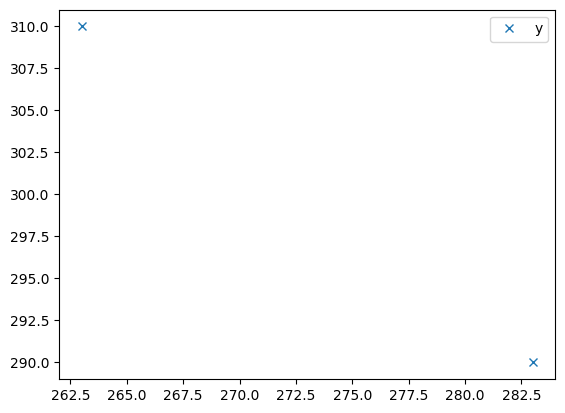

In [80]:
u = u0 + 273
y = y0

B = np.array([[1,263],[1,283]])
print(B)
print(B.T@B)
print(np.linalg.eig(B))

plt.plot(u, y, 'x', label='y')
plt.legend()


## Contour plot

Ths is nasty - hard to optimise.

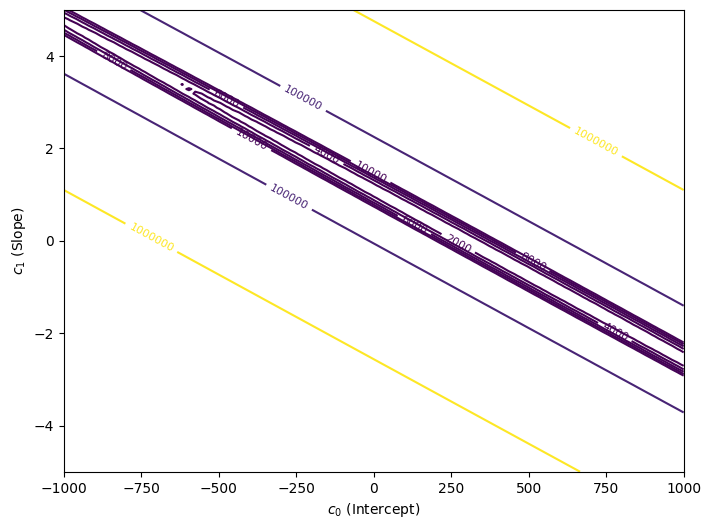

In [81]:
C0, C1 = np.mgrid[-1000:1000:100j, -5:5:100j]
mse_vectorized = np.vectorize(lambda c0, c1: mse(np.array([c0, c1])))
Z = mse_vectorized(C0, C1)

plt.figure(figsize=(8, 6))
custom_levels = [2000, 4000, 6000, 8000, 1e4, 1e5, 1e6]
contours = plt.contour(C0, C1, Z, levels=custom_levels, cmap='viridis')
plt.clabel(contours, inline=True, fontsize=8)
plt.xlabel('$c_0$ (Intercept)')
plt.ylabel('$c_1$ (Slope)')
plt.show()

## Wing Example


In [82]:
FB = 10000 # Body weight in N
# These are for a wing 1m x 1m:
kw = 30    # Wing weight
k1 = 0.001 # Induced drag for 1N of weight
k2 = 3.    # Surface drag

def wing(p1,p2):
  """Wing drag in N based on span p1 and chord p2 in m"""
  return (
      k1*kw**2 * p1**2/p2**2
        + 2*k1*kw*FB / p2
        + k1*FB**2 / p1**2
        + k2* p1*p2
    )

This is an alternative model with a slightly different structure, and a different shape.

In [83]:
if False:
  FB = 10000 # Body weight in N
  # These are for a wing 1m x 1m:
  kw = 5.    # Wing weight
  k1 = 0.002  # Induced drag for 1N of weight
  k2 = 3.   # Surface drag
  def wing(p1,p2):
    """Wing drag in N based on span p1 and chord p2 in m"""
    return (
        k1*kw**2 * p1**2/p2
          + 2*k1*kw*FB / p2
          + k1*FB**2 / p1**2/p2
          + k2* p1*p2
      )

## Contour Plot

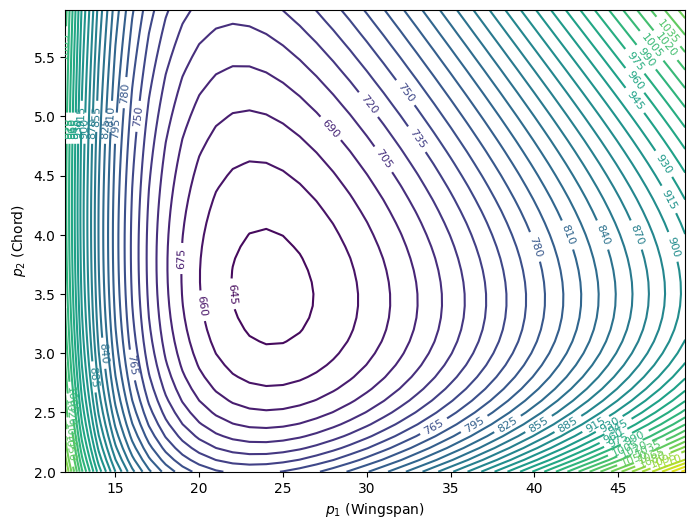

In [84]:
p1, p2 = np.mgrid[12:50:1, 2:6:0.1]
J = wing(p1,p2)

plt.figure(figsize=(8, 6))
contours = plt.contour(p1, p2, J, levels=50, cmap='viridis')
plt.clabel(contours, inline=True, fontsize=8)
plt.xlabel('$p_1$ (Wingspan)')
plt.ylabel('$p_2$ (Chord)')
plt.show()

## Different coordinates

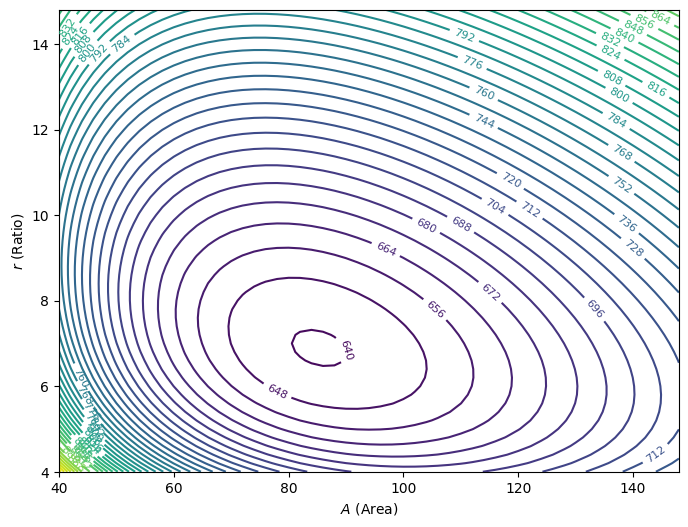

In [85]:
A, r = np.mgrid[40:150:2, 4:15:0.2]
J = wing((A*r)**0.5,(A/r)**0.5)

plt.figure(figsize=(8, 6))
contours = plt.contour(A, r, J, levels=50, cmap='viridis')
plt.clabel(contours, inline=True, fontsize=8)
plt.xlabel('$A$ (Area)')
plt.ylabel('$r$ (Ratio)')
plt.show()

## Or call an optimisation

In [86]:
import scipy.optimize as opt
uopt = opt.minimize(lambda p: wing(p[0],p[1]),np.array([20,5]))
print(uopt)
print(uopt.x)
print(np.linalg.inv(uopt.hess_inv))
print(np.linalg.eig(np.linalg.inv(uopt.hess_inv)))


  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 639.2986188028727
        x: [ 2.422e+01  3.519e+00]
      nit: 8
      jac: [ 7.629e-06  7.629e-06]
 hess_inv: [[ 4.426e-01 -2.082e-02]
            [-2.082e-02  2.276e-02]]
     nfev: 27
     njev: 9
[24.21942258  3.51948204]
[[ 2.36076575  2.15957044]
 [ 2.15957044 45.91181192]]
EigResult(eigenvalues=array([ 2.25394093, 46.01863675]), eigenvectors=array([[-0.99877881, -0.04940537],
       [ 0.04940537, -0.99877881]]))


## Validation plot

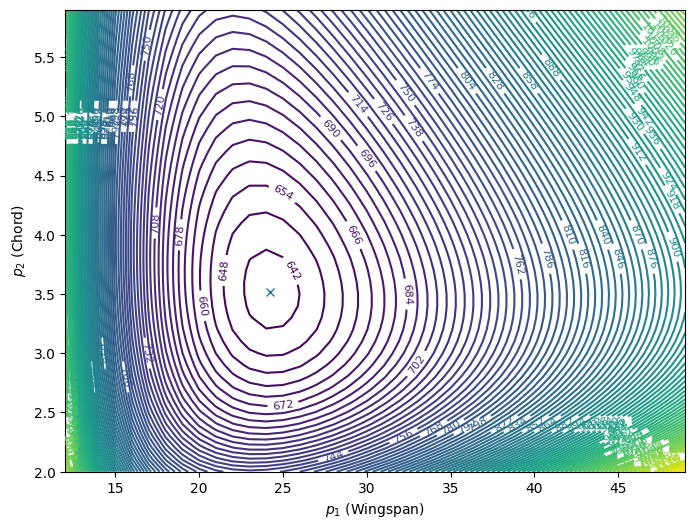

In [87]:
p1, p2 = np.mgrid[12:50:1, 2:6:0.1]
J = wing(p1,p2)

plt.figure(figsize=(8, 6))
contours = plt.contour(p1, p2, J, levels=100, cmap='viridis')
plt.plot(uopt.x[0],uopt.x[1],'x',label='Optimum')
plt.clabel(contours, inline=True, fontsize=8)
plt.xlabel('$p_1$ (Wingspan)')
plt.ylabel('$p_2$ (Chord)')
plt.show()

In [88]:
np.min(J)

np.float64(639.3580498866213)

## Review

Now we are talking!

This solves a real engineering problem.

Not a complex one, but the method scales nicely to small to medium scale problems.